## **Практическая работа 1. Уравнение фильтрации**

Решить $B(p)p_t-\operatorname{div}(C(p)\nabla p)=0$ в прямоугольнике
$0<x<200$, $0<y<100$ м. Начальное давление 10 МПа.
На верхней половине левого края давление 18 МПа, на остальных сторонах поток 0.

$B(p)=\rho_0[1+c_f(p-p_0)]\phi c_t$,
$C(p)=\rho_0[1+c_f(p-p_0)]k/\mu$.

In [1]:
%matplotlib inline
from dolfin import *
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
from pathlib import Path

Path('results').mkdir(exist_ok=True)
set_log_level(LogLevel.ERROR)
L, H = 200., 100.
Nx, Ny = 40, 20
tau = 3600.
M = 24
k, mu = 5e-14, 0.001
ct, cf = 2e-9, 5e-6
fi, ro0 = 0.2, 900.
p0, g = 10e6, 18e6

### Сетка и граничные условия

In [2]:
mesh = RectangleMesh(Point(0, 0), Point(L, H), Nx, Ny)
V = FunctionSpace(mesh, 'P', 1)

class LeftTopBoundary(SubDomain):
    def inside(self, x, on_boundary):
        return on_boundary and near(x[0], 0.) and x[1] >= H/2 - DOLFIN_EPS

bc = DirichletBC(V, Constant(g), LeftTopBoundary())
p = TrialFunction(V)
v = TestFunction(V)
p_old = interpolate(Constant(p0), V)
p_new = Function(V)

### Вариационная задача

Коэффициенты берём с прошлого слоя, неизвестное давление — с нового:
$\int B(p^n)p^{n+1}v+\tau\int C(p^n)\nabla p^{n+1}\cdot\nabla v
=\int B(p^n)p^n v$.

У диффузионного члена знак **плюс** по исходному уравнению.
В слабой форме PDF напечатан минус — здесь эта опечатка исправлена.

In [3]:
def B(p):
    return ro0 * (1 + cf * (p-p0)) * fi * ct


def C(p):
    return ro0 * (1 + cf * (p-p0)) / mu * k


a = B(p_old)*p*v*dx + tau*C(p_old)*inner(grad(p), grad(v))*dx
l = B(p_old)*p_old*v*dx

### Расчёт по времени

In [4]:
file = File('results/pressure.pvd')
file << (p_old, 0.)
time = []
mean_pressure = []
balance = []
snapshots = []
for j in range(M):
    A = assemble(a)
    b = assemble(l)
    A_bc, b_bc = A.copy(), b.copy()
    bc.apply(A_bc, b_bc)
    solve(A_bc, p_new.vector(), b_bc, 'lu')
    # Приток через границу с заданным давлением — реакция исходной системы.
    reaction = b.copy()
    A.mult(p_new.vector(), reaction)
    reaction.axpy(-1., b)
    inflow = reaction.get_local()[list(bc.get_boundary_values())].sum()
    storage = assemble(B(p_old)*(p_new-p_old)*dx)
    balance.append(abs(storage-inflow) / max(abs(storage), 1.))
    t = (j+1)*tau
    file << (p_new, t)
    time.append(t/3600)
    mean_pressure.append(assemble(p_new*dx)/(L*H)/1e6)
    print(f't = {t/3600:2g} ч, среднее давление = {mean_pressure[-1]:.6f} МПа')
    if j+1 in [1, 6, 12, 24]:
        snapshots.append((t/3600, p_new.compute_vertex_values(mesh).copy()))
    p_old.assign(p_new)

print('Максимальная ошибка баланса:', max(balance))
print('Перепад cf·Δp:', cf*(g-p0))
assert max(balance) < 1e-7
values = p_new.compute_vertex_values(mesh)
assert values.min() >= p0-1 and values.max() <= g+1
np.savez('results/filtration.npz', xy=mesh.coordinates(), cells=mesh.cells(),
         p=values, time=time, mean_pressure=mean_pressure, balance=balance)
np.savetxt('results/history.csv', np.column_stack([time,mean_pressure,balance]),
           delimiter=',', header='time_h,mean_pressure_mpa,balance', comments='')

t =  1 ч, среднее давление = 10.529629 МПа
t =  2 ч, среднее давление = 11.265903 МПа
t =  3 ч, среднее давление = 11.791104 МПа
t =  4 ч, среднее давление = 12.209585 МПа
t =  5 ч, среднее давление = 12.563280 МПа
t =  6 ч, среднее давление = 12.868947 МПа
t =  7 ч, среднее давление = 13.136868 МПа
t =  8 ч, среднее давление = 13.374607 МПа
t =  9 ч, среднее давление = 13.587818 МПа
t = 10 ч, среднее давление = 13.780773 МПа
t = 11 ч, среднее давление = 13.956760 МПа
t = 12 ч, среднее давление = 14.118354 МПа
t = 13 ч, среднее давление = 14.267607 МПа
t = 14 ч, среднее давление = 14.406173 МПа
t = 15 ч, среднее давление = 14.535406 МПа
t = 16 ч, среднее давление = 14.656423 МПа
t = 17 ч, среднее давление = 14.770153 МПа
t = 18 ч, среднее давление = 14.877381 МПа
t = 19 ч, среднее давление = 14.978769 МПа
t = 20 ч, среднее давление = 15.074883 МПа
t = 21 ч, среднее давление = 15.166210 МПа
t = 22 ч, среднее давление = 15.253169 МПа
t = 23 ч, среднее давление = 15.336126 МПа
t = 24 ч, с

### Визуализация решения

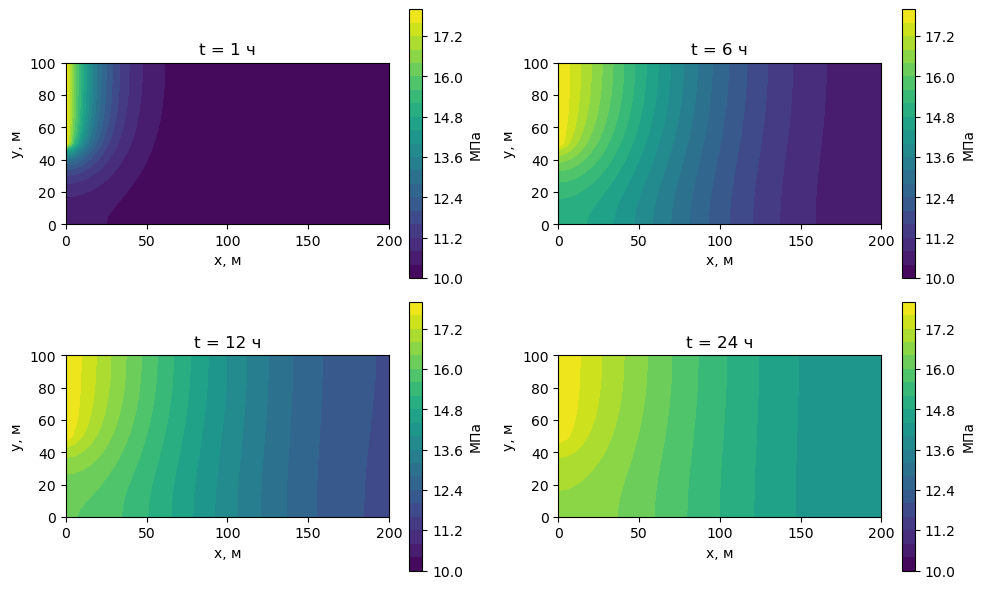

In [5]:
xy = mesh.coordinates()
tri = mtri.Triangulation(xy[:,0], xy[:,1], mesh.cells())
fig, ax = plt.subplots(2, 2, figsize=(10, 6))
for a, (hour, values) in zip(ax.flat, snapshots):
    im = a.tricontourf(tri, values/1e6, levels=np.linspace(10,18,21))
    fig.colorbar(im, ax=a, label='МПа')
    a.set(title=f't = {hour:g} ч', xlabel='x, м', ylabel='y, м', aspect='equal')
plt.tight_layout()
plt.savefig('results/filtration.png', dpi=150)
plt.show()

### Вывод

Давление растёт от участка нагнетания, среднее давление через сутки около
15.4154 МПа. Проверен баланс между накоплением и притоком.

Коэффициент $c_f=5\cdot10^{-6}$ взят буквально из PDF. Для перепада 8 МПа
получается $c_f\Delta p=40$: это учебный расчёт с данными задания, а режим
малого изменения плотности при таком коэффициенте не выполняется.